# 01 - Exploratory data analysis

Exploratory analysis of the pulmonary-fibrosis hackathon dataset.

The private dataset is **not included** in this repository. This notebook only produces aggregate summaries and visualizations; it deliberately avoids displaying raw participant rows.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)

DATA_FILENAME = "reto_fibrosis_pulmonar_dataset_participantes.tsv"

def resolve_data_file(filename):
    candidates = [Path("data") / filename, Path(filename)]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        f"Could not find {filename}. Put the authorized dataset in ./data/ "
        "or next to this notebook. Do not commit it to GitHub."
    )

data_path = resolve_data_file(DATA_FILENAME)
df = pd.read_csv(data_path, sep="\t")
df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [2]:
missing = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("Missing_Percent")
    .to_frame()
)

display(missing[missing["Missing_Percent"] > 0].head(5))

,Missing_Percent
time_visit3,16.6
fvc_v3,16.6
NPX_BMP26A,3.7
NPX_MMP1411,3.5
NPX_APOB490R1,3.5


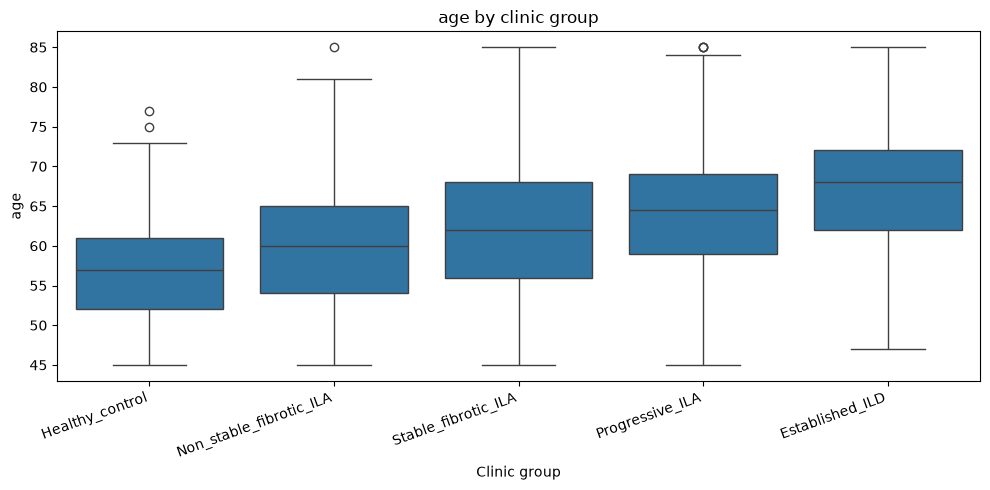

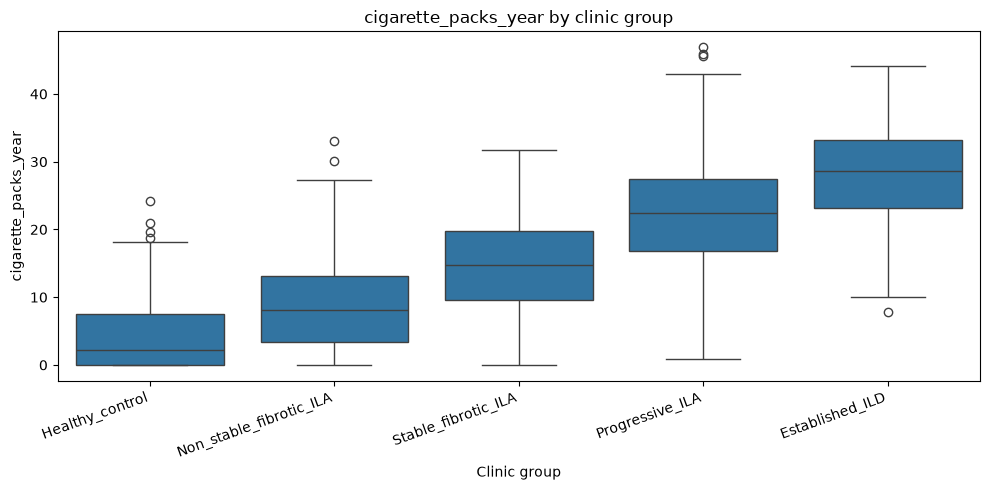

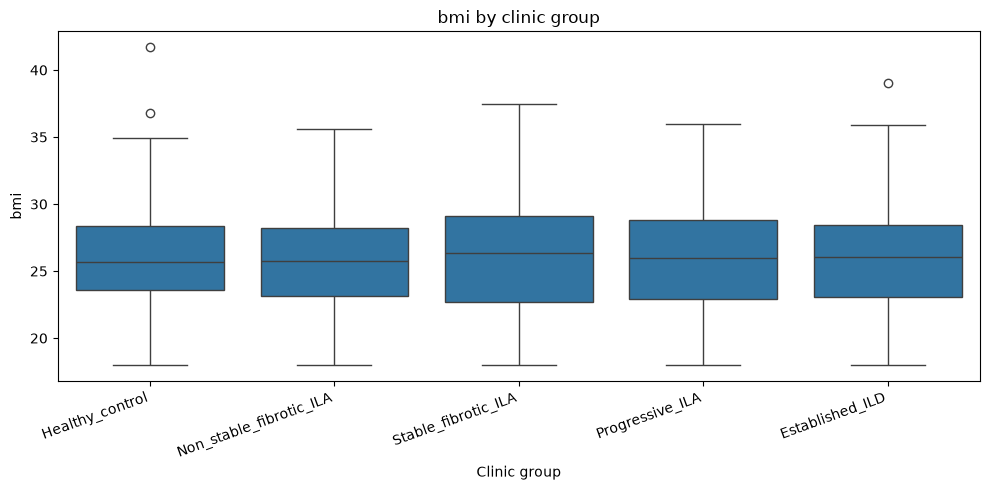

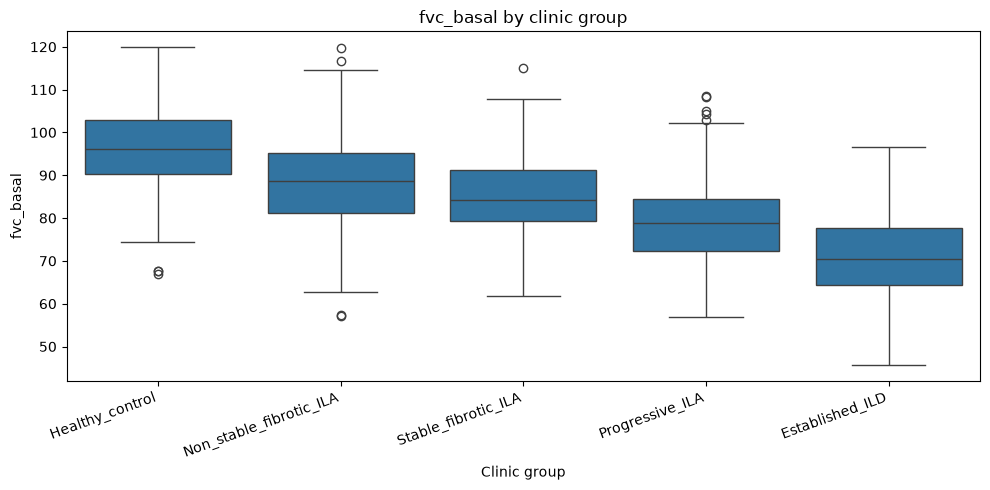

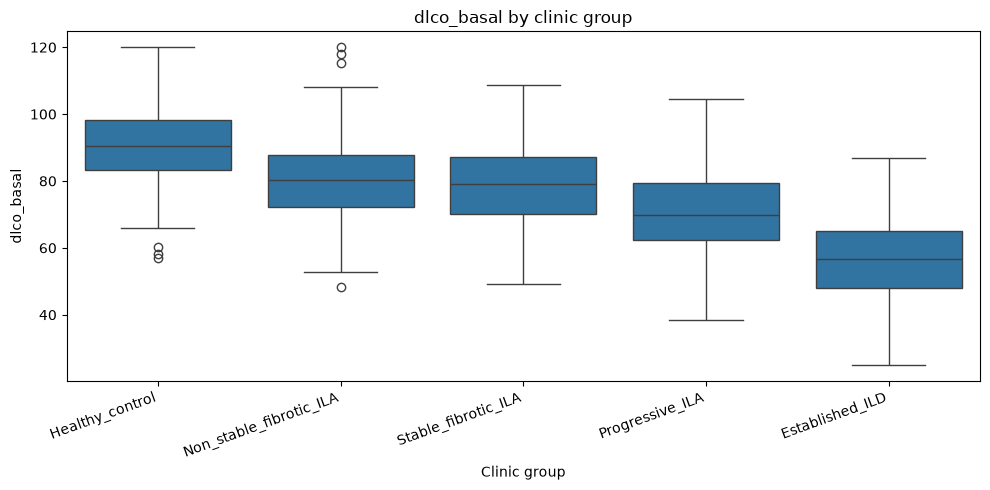

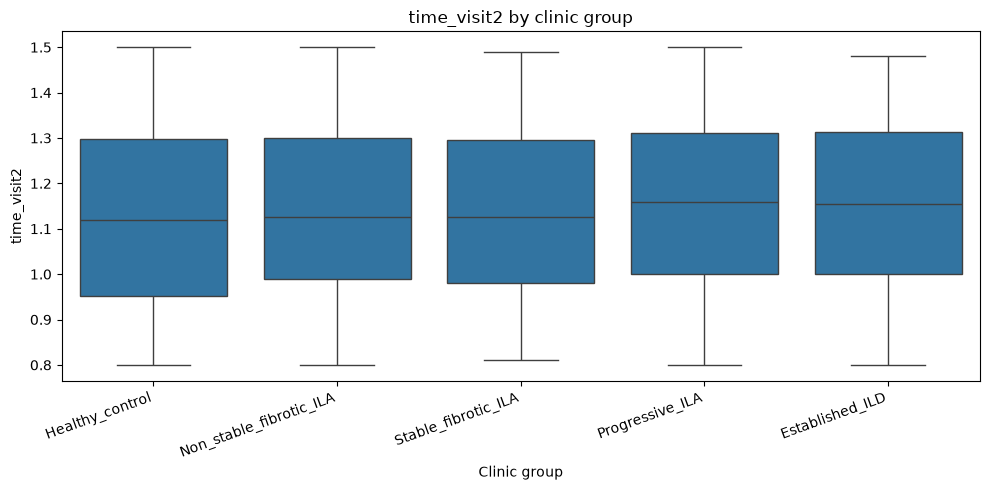

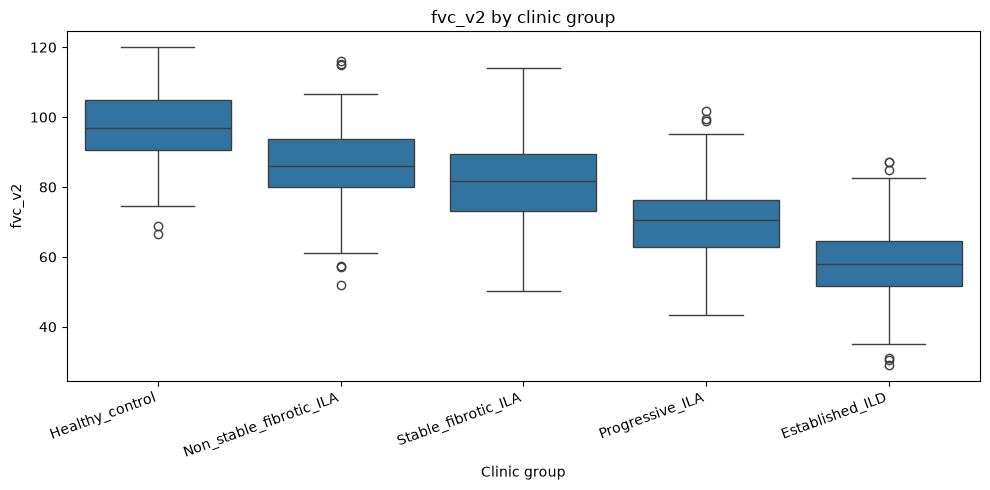

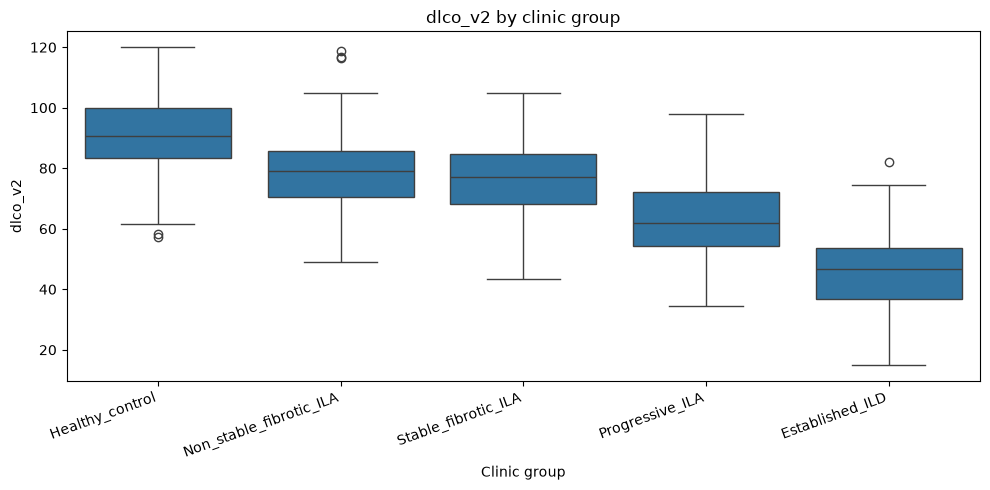

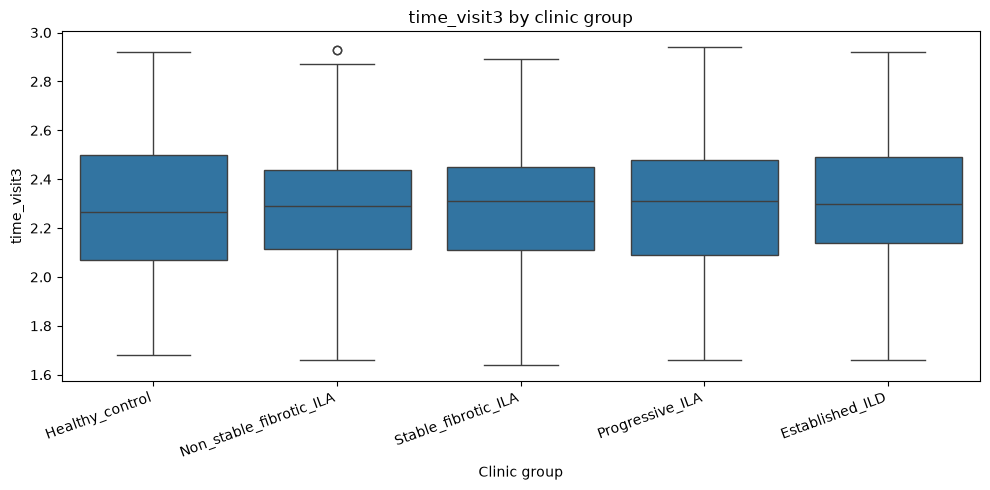

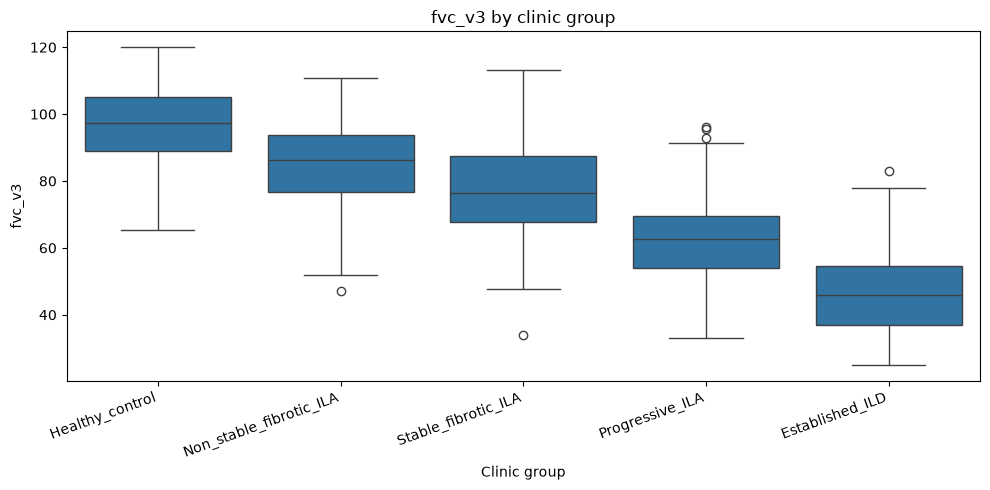

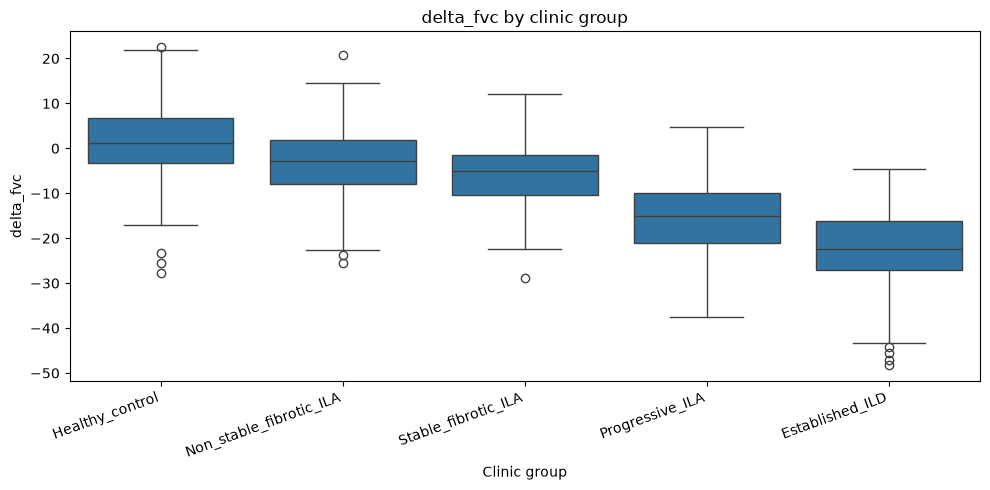

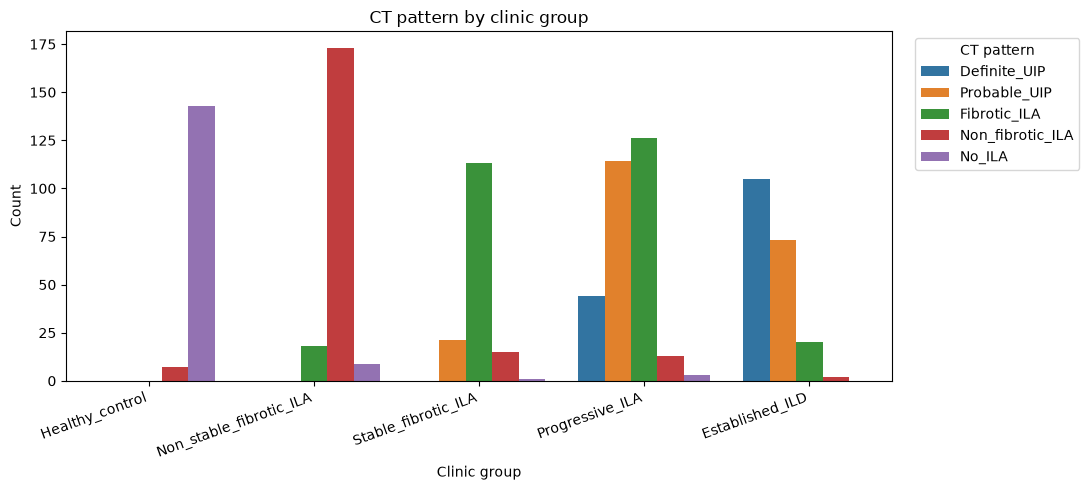

In [3]:
CLINIC_ORDER = [
    "Healthy_control",
    "Non_stable_fibrotic_ILA",
    "Stable_fibrotic_ILA",
    "Progressive_ILA",
    "Established_ILD",
]

CLINICAL_NUMERIC = [
    "age",
    "cigarette_packs_year",
    "bmi",
    "fvc_basal",
    "dlco_basal",
    "time_visit2",
    "fvc_v2",
    "dlco_v2",
    "time_visit3",
    "fvc_v3",
    "delta_fvc",
]

variables = [v for v in CLINICAL_NUMERIC if v in df.columns]

for variable in variables:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x="clinic_group", y=variable, order=CLINIC_ORDER)
    plt.title(f"{variable} by clinic group")
    plt.xlabel("Clinic group")
    plt.ylabel(variable)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

if "ct_pattern" in df.columns:
    plt.figure(figsize=(11, 5))
    sns.countplot(
        data=df,
        x="clinic_group",
        hue="ct_pattern",
        order=CLINIC_ORDER,
    )
    plt.title("CT pattern by clinic group")
    plt.xlabel("Clinic group")
    plt.ylabel("Count")
    plt.xticks(rotation=20, ha="right")
    plt.legend(title="CT pattern", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## What I looked for

The exploratory step compared clinical variables and shortlisted proteins across the five clinical groups. The most useful visual patterns were then followed up with supervised classification experiments in the next notebooks.